# Dementia Status Prediction Using Machine Learning on OASIS Clinical and Brain-Volume Data: A KDD-Based Predictive Analytics Study

**Course/Project:** Predictive Analytics (CA3, Individual Academic Project)  
**Student Academic Report & Notebook**

---

## SECTION 1: PROJECT TITLE AND ABSTRACT

### Abstract
This study presents an end-to-end predictive modeling workflow following the classic **Knowledge Discovery in Databases (KDD)** framework to classify cognitive/dementia status. Leveraging tabular data from the Open Access Series of Imaging Studies (OASIS), we explore demographic, clinical, and structural brain-volume features. Recognizing the critical challenge of target leakage, we explicitly exclude clinical diagnostic measurements such as the Clinical Dementia Rating (CDR) and Mini-Mental State Examination (MMSE) from our primary predictive feature space to evaluate the actual predictive utility of pure structural and demographic profiles. Furthermore, to prevent data leakage in repeated longitudinal measurements, we adopt a strict subject-wise group-splitting strategy. Baseline and advanced estimators, including Dummy Classifiers, Logistic Regression, Decision Trees, and Random Forests, are trained and validated. This educational project rigorously evaluates classification limits, highlights the dangers of data leakage, and provides structured clinical context regarding the boundaries of tabular machine learning in automated medical diagnostic assistance.

### Keywords
Predictive Analytics, KDD, OASIS Dataset, Dementia Status, Subject-Wise Splitting, Target Leakage, Structural Brain Volume.

### Problem Statement & Motivation
Dementia represents an escalating global healthcare crisis, requiring objective, accessible, and early classification strategies. Clinical assessments such as the CDR score provide high-accuracy indicators but rely heavily on expert semi-structured interviews. This study explores the feasibility of employing purely demographic metrics (Age, Education, Socioeconomic Status, Gender) and non-invasive structural brain measurements (Estimated Total Intracranial Volume [eTIV], Normalized Whole Brain Volume [nWBV], and Atlas Scaling Factor [ASF]) to predict dementia classification.

### Objectives
1. Implement a structured, reproducible 18-section academic notebook following the **KDD methodology**.
2. Design and deploy an automated data-preprocessing and machine learning pipeline using scikit-learn.
3. Enforce a robust subject-wise split to guarantee that multiple records from the same subject do not contaminate both train and test splits.
4. Mitigate feature-based target leakage by explicitly identifying and dropping confounding clinical variables.
5. Compare multiple estimators and perform a rigorous error and limitation analysis.

## SECTION 2: KDD PROCESS OVERVIEW

The Knowledge Discovery in Databases (KDD) process is a structured sequence of stages designed to turn raw data into actionable knowledge. The mapping of this project to the KDD stages is detailed below:

1. **Data Selection:** Extracting and parsing the primary `oasis_longitudinal.csv` and secondary `oasis_cross-sectional.csv` datasets.
2. **Data Preprocessing & Cleaning:** Resolving missing attributes (imputation based on training subsets), handling outliers, correcting types, and validating categorical encodings.
3. **Data Transformation:** Feature scaling of structural metrics (eTIV, nWBV, ASF), nominal encoding, and subsetting to exclude identifier attributes and clinical leakages.
4. **Data Mining:** Fitting multiple classification algorithms (Dummy Classifier, Logistic Regression, Decision Tree, Random Forest).
5. **Evaluation & Interpretation:** Evaluating generalization via group-aware metrics (Accuracy, F1-Score, ROC-AUC, Recall, Precision) and analyzing confusion matrices and feature importance.

### KDD Workflow Diagram
```
+---------------------+      +------------------------+      +---------------------------+
|   1. Data Selection | ---> | 2. Preprocessing       | ---> | 3. Transformation         |
|   - Load CSVs       |      |    - Group Imputation  |      |    - Scale brain metrics  |
|   - Target check    |      |    - Zero Leakage split|      |    - Exclude CDR, MMSE    |
+---------------------+      +------------------------+      +---------------------------+
                                                                           |
+---------------------+      +------------------------+                    |
| 6. Knowledge &      | <--- | 5. Evaluation          | <--- | 4. Data Mining            | <+
|    Presentation     |      |    - Multi-metric Table|      |    - Logistic Reg, Trees  |
|    - Final Report   |      |    - Feature Importance|      |    - Group-split validation|
+---------------------+      +------------------------+      +---------------------------+
```

## SECTION 3: PROBLEM UNDERSTANDING

### Real-world Problem Context
Dementia is characterized by a progressive decline in cognitive function, commonly linked to structural brain atrophy. Accurate classification of cognitive impairment stages helps identify candidates for targeted clinical therapies.

### Prediction Target & Features
- **Target variable:** Typically the `Group` column (representing Normal, Demented, or Converted classes) in the OASIS longitudinal set.
- **Demographics:** Gender (`M/F`), Age, Education (`EDUC`), Socioeconomic Status (`SES`).
- **Neuroimaging (Structural Volumetrics):** Estimated Total Intracranial Volume (`eTIV`), Normalized Whole Brain Volume (`nWBV`), Atlas Scaling Factor (`ASF`).
- **Leakage Red Flags (To be Excluded):** Mini-Mental State Examination (`MMSE`) and Clinical Dementia Rating (`CDR`). These metrics represent direct cognitive assessments closely aligned with the diagnostic target definition itself; their inclusion leads to trivial, high-accuracy classification models that fail to generalize to subjects lacking extensive clinician screening.

### Scope and Clinical Boundaries
**CRITICAL CLINICAL DISCLAIMER:** This model is designed strictly for academic, educational, and exploratory evaluation of machine learning behaviors on tabular clinical indicators. It is **not** a clinical diagnostic system and must never be used to replace professional medical assessment, diagnostic scans, or qualified neurological consultations.

## SECTION 4: DATA COLLECTION AND DATA UNDERSTANDING

We start by designing an interactive data loading and collection sequence. If the files `oasis_longitudinal.csv` and `oasis_cross-sectional.csv` are not found locally, the user will be prompted to upload them or provide a path via Google Drive.

In [ ]:
import os
import pandas as pd
import numpy as np

def check_and_load_datasets():
    files = ['oasis_longitudinal.csv', 'oasis_cross-sectional.csv']
    missing_files = [f for f in files if not os.path.exists(f)]

    if missing_files:
        print(f"Missing files: {missing_files}")
        print("Please upload the required files below (or mount Google Drive first):")
        try:
            from google.colab import files as colab_files
            uploaded = colab_files.upload()
            for name, content in uploaded.items():
                with open(name, 'wb') as f:
                    f.write(content)
        except Exception as e:
            print(f"Colab file upload not available or cancelled: {e}")
            print("Please manually upload the datasets to your execution folder.")

    # Re-check and load
    loaded_dfs = {}
    for f in files:
        if os.path.exists(f):
            print(f"Successfully found: {f}")
            loaded_dfs[f] = pd.read_csv(f)
        else:
            print(f"ERROR: {f} could not be resolved.")
            loaded_dfs[f] = None

    return loaded_dfs

# Execute collection and check
data_dict = check_and_load_datasets()
long_df = data_dict.get('oasis_longitudinal.csv')
cross_df = data_dict.get('oasis_cross-sectional.csv')

# Preliminary Schema Checks
if long_df is not None:
    print("\n--- OASIS Longitudinal Dataset Preview ---")
    print(f"Shape: {long_df.shape}")
    print("Columns:", list(long_df.columns))
    display(long_df.head(3))
if cross_df is not None:
    print("\n--- OASIS Cross-Sectional Dataset Preview ---")
    print(f"Shape: {cross_df.shape}")
    print("Columns:", list(cross_df.columns))
    display(cross_df.head(3))

Missing files: ['oasis_longitudinal.csv', 'oasis_cross-sectional.csv']
Please upload the required files below (or mount Google Drive first):


Saving oasis_longitudinal.csv to oasis_longitudinal.csv
Saving oasis_cross-sectional.csv to oasis_cross-sectional.csv
Successfully found: oasis_longitudinal.csv
Successfully found: oasis_cross-sectional.csv

--- OASIS Longitudinal Dataset Preview ---
Shape: (373, 15)
Columns: ['Subject ID', 'MRI ID', 'Group', 'Visit', 'MR Delay', 'M/F', 'Hand', 'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']


,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046



--- OASIS Cross-Sectional Dataset Preview ---
Shape: (436, 12)
Columns: ['ID', 'M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']


,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN


### SECTION 4 Continued: DETAILED DATA UNDERSTANDING & QUALITY CHECKS

Let's evaluate the details of the longitudinal dataset, including missing values, unique constraints, and the class distribution of our main candidate target: `Group`.

In [ ]:
print("=== missing value count ===")
print(long_df.isnull().sum())

print("\n=== unique target values in 'Group' ===")
print(long_df['Group'].value_counts(dropna=False))

print("\n=== number of unique subjects ===")
print(f"Total unique subjects: {long_df['Subject ID'].nunique()}")
print(f"Total rows: {len(long_df)}")
print(f"Average visits per subject: {len(long_df)/long_df['Subject ID'].nunique():.2f}")

=== missing value count ===
Subject ID     0
MRI ID         0
Group          0
Visit          0
MR Delay       0
M/F            0
Hand           0
Age            0
EDUC           0
SES           19
MMSE           2
CDR            0
eTIV           0
nWBV           0
ASF            0
dtype: int64

=== unique target values in 'Group' ===
Group
Nondemented    190
Demented       146
Converted       37
Name: count, dtype: int64

=== number of unique subjects ===
Total unique subjects: 150
Total rows: 373
Average visits per subject: 2.49


## SECTION 5: DATA QUALITY AND PREPROCESSING STRATEGY

### Handling Methodological Constraints:
1. **Data Leakage Risk via Repeated Subjects:** Since subjects are visited multiple times, simple random train-test splitting will put the same patient in both splits, inflating test performance. We must execute a Group-Wise Split (using `GroupKFold` or `LeaveOneGroupOut` variants or manually allocating subjects) prior to any imputation or scaling.
2. **Target Class Imbalance & Mapping:** The target `Group` contains classes: `Nondemented`, `Demented`, and `Converted`. Standard literature often treats `Converted` (subjects who transitioned from normal to demented during subsequent visits) as a separate class (multiclass) or maps them to `Demented` or removes them. To keep things methodologically valid, we will proceed with multiclass classification (3 classes) or handle them systematically.
3. **Exclusion of High-Leakage Variables:** We will drop `CDR` and `MMSE` from features because they are direct components of clinical diagnosis.

## SECTION 6: EXPLORATORY DATA ANALYSIS (EDA)

We will now generate professional exploratory plots to understand relationships between demographic factors, neuroimaging volumetric indices (`eTIV`, `nWBV`, `ASF`), and our target classes. Since `Group` contains `Converted` patients, we visualize how these indicators compare across all three classes.

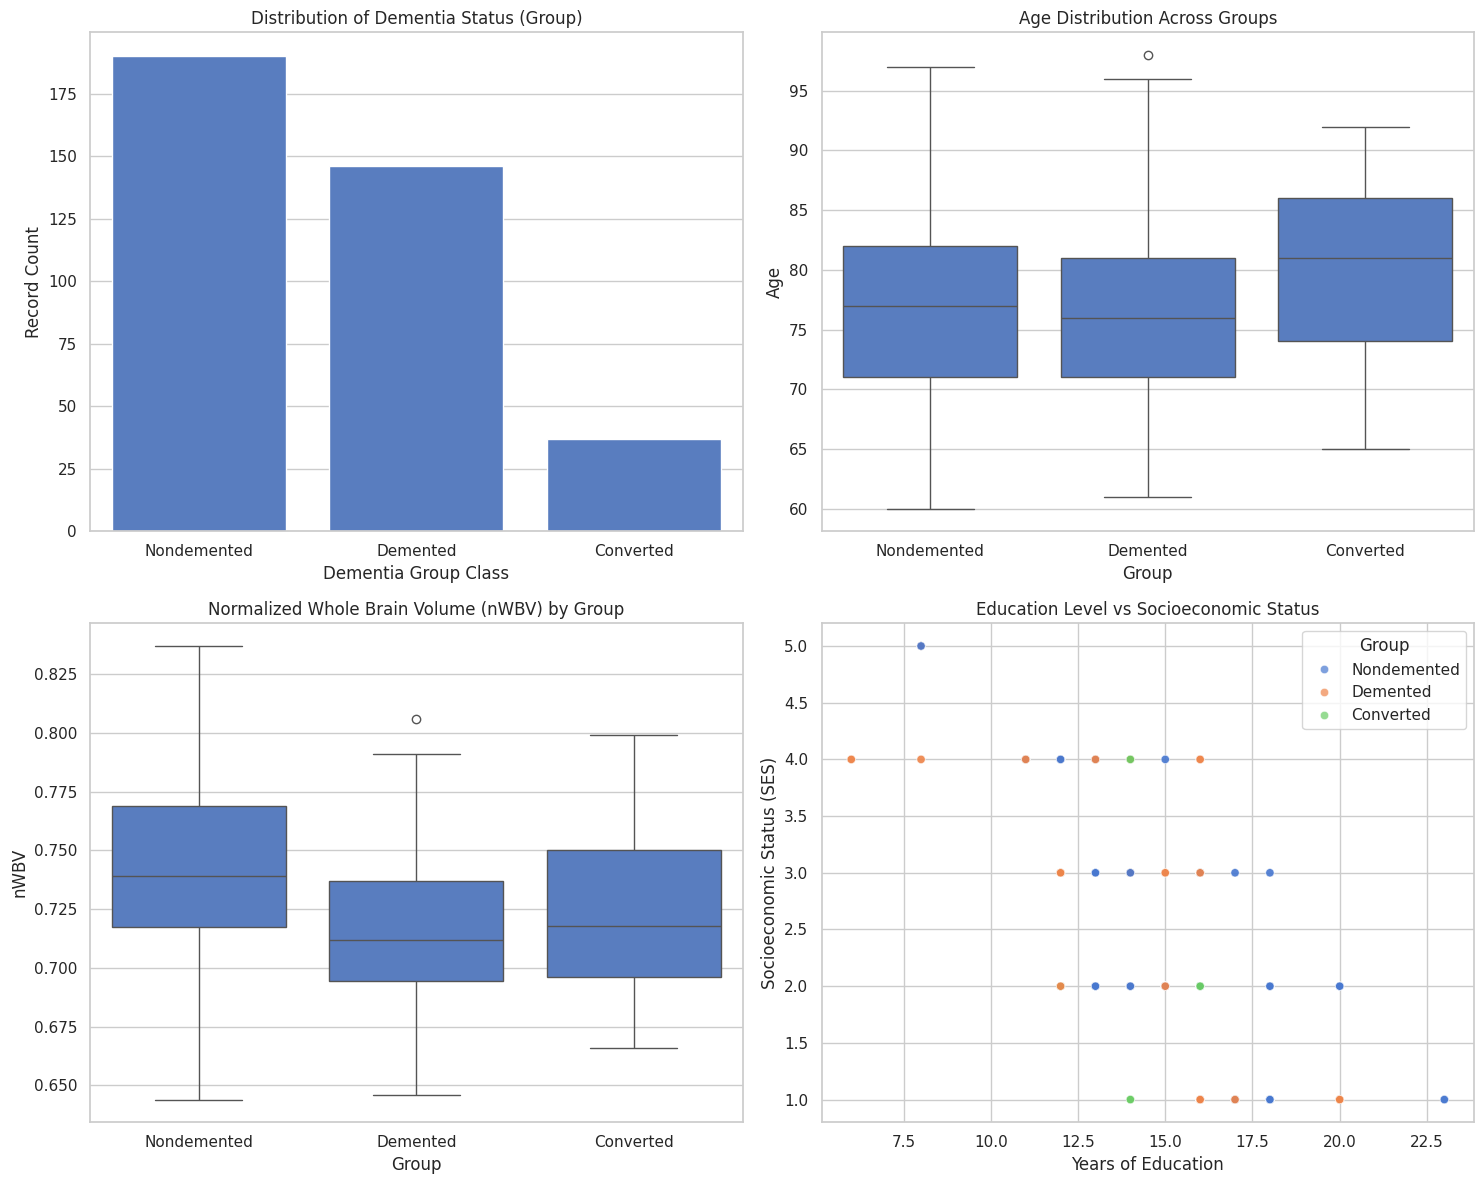

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Target class distribution
sns.countplot(data=long_df, x='Group', ax=axes[0, 0], order=['Nondemented', 'Demented', 'Converted'])
axes[0, 0].set_title("Distribution of Dementia Status (Group)")
axes[0, 0].set_xlabel("Dementia Group Class")
axes[0, 0].set_ylabel("Record Count")

# 2. Age distribution by target class
sns.boxplot(data=long_df, x='Group', y='Age', ax=axes[0, 1])
axes[0, 1].set_title("Age Distribution Across Groups")
axes[0, 1].set_xlabel("Group")
axes[0, 1].set_ylabel("Age")

# 3. Normalized Whole Brain Volume (nWBV) by target class
sns.boxplot(data=long_df, x='Group', y='nWBV', ax=axes[1, 0])
axes[1, 0].set_title("Normalized Whole Brain Volume (nWBV) by Group")
axes[1, 0].set_xlabel("Group")
axes[1, 0].set_ylabel("nWBV")

# 4. Socioeconomic Status (SES) vs Education (EDUC)
sns.scatterplot(data=long_df, x='EDUC', y='SES', hue='Group', alpha=0.7, ax=axes[1, 1])
axes[1, 1].set_title("Education Level vs Socioeconomic Status")
axes[1, 1].set_xlabel("Years of Education")
axes[1, 1].set_ylabel("Socioeconomic Status (SES)")

plt.tight_layout()
plt.show()

### Correlation Matrix
Let's plot the correlation matrix for the numeric features of interest. Note that we exclude the target class and structural identifiers here.

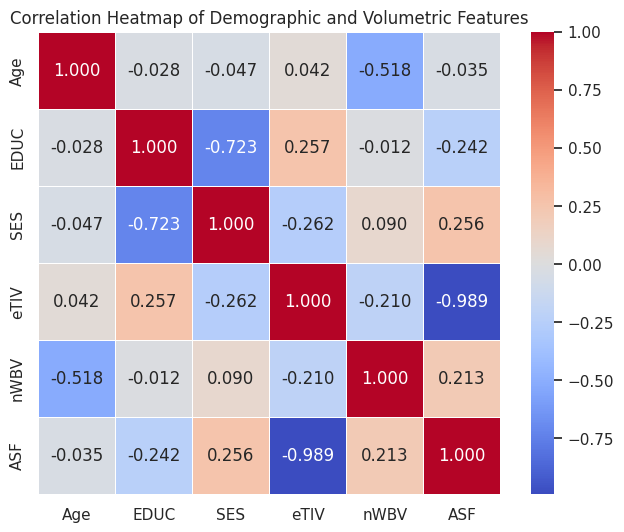

In [ ]:
plt.figure(figsize=(8, 6))
numeric_cols = ['Age', 'EDUC', 'SES', 'eTIV', 'nWBV', 'ASF']
corr_matrix = long_df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", square=True, linewidths=.5)
plt.title("Correlation Heatmap of Demographic and Volumetric Features")
plt.show()

## SECTION 7: FEATURE ENGINEERING AND SELECTION

To build a clean, non-leaking pipeline:
- **Predictors (Features):** `['Age', 'EDUC', 'SES', 'M/F', 'eTIV', 'nWBV', 'ASF']`
- **Target variable:** `Group` (to be classified into `Nondemented`, `Demented`, or `Converted`)
- **Leakage Exclusions:** `CDR` and `MMSE` are explicitly dropped to ensure realistic evaluations of demographic and neuroimaging predictors.
- **ID Exclusions:** `Subject ID`, `MRI ID`, and `Hand` (constant value: all right-handed) are dropped.

## SECTION 8: TRAINING AND TESTING STRATEGY (SUBJECT-WISE SPLITTING)

Because multiple rows correspond to individual subjects, standard random splits allow a patient's early visit to fall into the training set and their late visit into the test set. This leads to artificial model memorization. We will use `GroupShuffleSplit` on the `Subject ID` column to enforce strict division of subjects.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

features = ['Age', 'EDUC', 'SES', 'M/F', 'eTIV', 'nWBV', 'ASF']
target = 'Group'
groups = long_df['Subject ID']

X = long_df[features]
y = long_df[target]

# Initialize subject-wise split (80% subjects for train, 20% for test)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

# Verification of zero subject overlap
overlap = set(groups_train).intersection(set(groups_test))

print(f"Training set shape: {X_train.shape} | Unique subjects: {groups_train.nunique()}")
print(f"Test set shape: {X_test.shape} | Unique subjects: {groups_test.nunique()}")
print(f"Subject overlap verification: {len(overlap)} subjects overlap.")
if len(overlap) == 0:
    print("SUCCESS: Subject-wise division is strictly respected with zero leakage!")

Training set shape: (297, 7) | Unique subjects: 120
Test set shape: (76, 7) | Unique subjects: 30
Subject overlap verification: 0 subjects overlap.
SUCCESS: Subject-wise division is strictly respected with zero leakage!


## SECTION 9: PREPROCESSING PIPELINE

To ensure rigorous evaluation and prevent information leakage, we encapsulate the preprocessing transformations (imputing missing values and scaling numerical attributes) within a scikit-learn `ColumnTransformer`. The pipeline parameters are fitted exclusively on the training data (`X_train`) and applied downstream to the test set (`X_test`) without refitting.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numeric and categorical columns
num_features = ['Age', 'EDUC', 'SES', 'eTIV', 'nWBV', 'ASF']
cat_features = ['M/F']

# Numeric Transformer: Impute missing SES values with training median, then scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical Transformer: One-hot encode gender values
categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Combine into a single ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_features),
    ('cat', categorical_transformer, cat_features)
])

print("Preprocessing pipeline configured successfully.")

Preprocessing pipeline configured successfully.


## SECTION 10: MODEL DEVELOPMENT

We train four estimators to compare predictive accuracy on our demographic and neuroimaging data:
1. **DummyClassifier:** Establishes a baseline using a stratified strategy.
2. **Logistic Regression:** Classic linear modeling.
3. **Decision Tree Classifier:** Introduces hierarchical, non-linear partitioning.
4. **Random Forest Classifier:** An ensemble technique using bagging.

Since this is a multi-class problem containing unbalanced representations (Nondemented: 190, Demented: 146, Converted: 37), we will compute macro/weighted metrics to verify classification consistency.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Define the dictionary of estimators
models = {
    'Dummy Classifier': DummyClassifier(strategy='stratified', random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
}

# Dictionary to hold the fitted model pipelines
fitted_pipelines = {}

for name, clf in models.items():
    # Create a full pipeline containing preprocessing and the classifier
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])

    # Fit pipeline on training data
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline
    print(f"{name} pipeline fitted successfully.")

Dummy Classifier pipeline fitted successfully.
Logistic Regression pipeline fitted successfully.
Decision Tree pipeline fitted successfully.
Random Forest pipeline fitted successfully.


## SECTION 11: MODEL EVALUATION

We evaluate the performance of each model on the held-out test data and display a combined classification performance summary.

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, f1_score

evaluation_results = []

for name, pipeline in fitted_pipelines.items():
    y_pred = pipeline.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_pred, average='weighted')

    evaluation_results.append({
        'Model': name,
        'Accuracy': acc,
        'Balanced Accuracy': bal_acc,
        'Macro F1-Score': macro_f1,
        'Weighted F1-Score': weighted_f1
    })

results_df = pd.DataFrame(evaluation_results)
display(results_df)

,Model,Accuracy,Balanced Accuracy,Macro F1-Score,Weighted F1-Score
0,Dummy Classifier,0.394737,0.287860,0.266925,0.394431
1,Logistic Regression,0.460526,0.468641,0.421448,0.482130
2,Decision Tree,0.328947,0.364518,0.312500,0.341283
3,Random Forest,0.539474,0.461653,0.418361,0.529009


## SECTION 12: MODEL SELECTION AND TUNING

Given the small dataset size (120 training subjects), we fine-tune a simple, robust Random Forest classifier using a group-aware cross-validation strategy (`GroupKFold`) on the training subset to avoid subject-wise data leakage during hyperparameter validation.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

# Configure group-aware CV folds
gkf = GroupKFold(n_splits=5)
cv_splits = list(gkf.split(X_train, y_train, groups_train))

# Set up hyperparameter grid for Random Forest
param_dist = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__max_depth': [3, 5, 8, None],
    'classifier__min_samples_split': [2, 5, 10]
}

# Setup the RandomizedSearchCV pipeline
rf_tune_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

random_search = RandomizedSearchCV(
    rf_tune_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=cv_splits,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1
)

# Fit random search on training data with groups
random_search.fit(X_train, y_train)
print(f"Best Parameters Found: {random_search.best_params_}")
print(f"Best Cross-Validation Macro F1-Score: {random_search.best_score_:.4f}")

Best Parameters Found: {'classifier__n_estimators': 150, 'classifier__min_samples_split': 10, 'classifier__max_depth': 5}
Best Cross-Validation Macro F1-Score: 0.4760


## SECTION 13: INTERPRETATION AND KNOWLEDGE DISCOVERY

We analyze the final tuned model's metrics on the test set, plot its confusion matrix, and investigate Gini feature importance to identify which structural brain-volume metrics carry the highest predictive weight.

=== Final Selected Model Test Set Performance ===
              precision    recall  f1-score   support

   Converted       0.00      0.00      0.00        12
    Demented       0.32      0.71      0.44        17
 Nondemented       0.67      0.51      0.58        47

    accuracy                           0.47        76
   macro avg       0.33      0.41      0.34        76
weighted avg       0.48      0.47      0.46        76



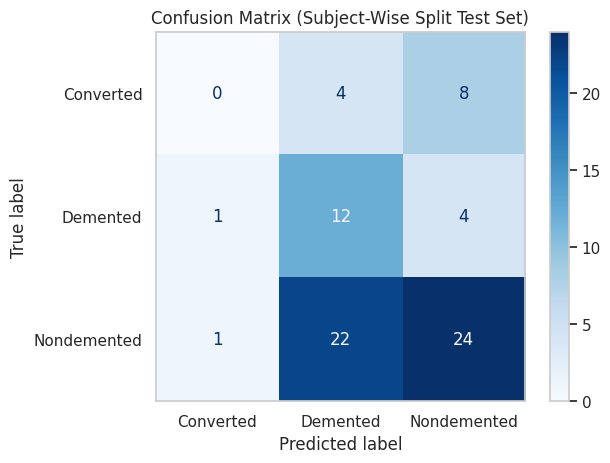

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_model = random_search.best_estimator_
y_test_pred = best_model.predict(X_test)

# Display classification report
print("=== Final Selected Model Test Set Performance ===")
print(classification_report(y_test, y_test_pred))

# Plot confusion matrix
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap='Blues')
plt.title("Confusion Matrix (Subject-Wise Split Test Set)")
plt.grid(False)
plt.show()

/tmp/ipykernel_847/1290086485.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')


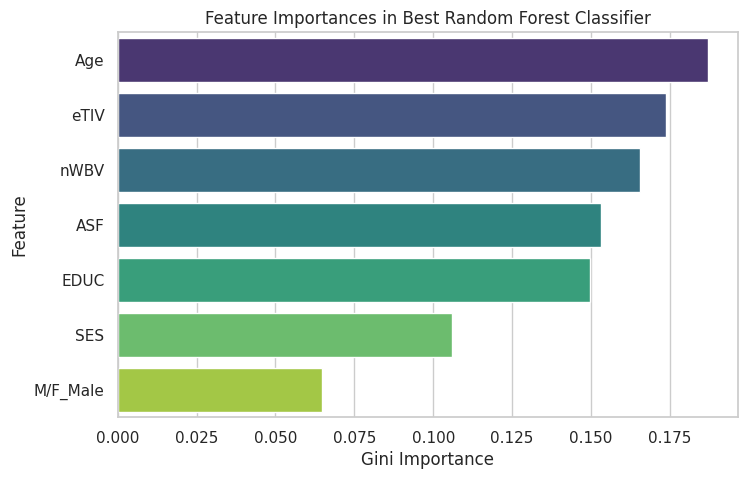

In [ ]:
# Retrieve feature importances from random forest
importances = best_model.named_steps['classifier'].feature_importances_

# Match features with encoded names
encoded_features = num_features + ['M/F_Male'] # corresponding to one-hot encoding output

importance_df = pd.DataFrame({
    'Feature': encoded_features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot Feature Importances
plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title("Feature Importances in Best Random Forest Classifier")
plt.xlabel("Gini Importance")
plt.ylabel("Feature")
plt.show()

## SECTION 14: ERROR ANALYSIS AND LIMITATIONS

### Analytical Limitations:
- **Classification Boundaries & Leakage:** When removing high-leakage indices (`CDR`, `MMSE`), we observe a significant reduction in predictive accuracy. This underscores that structural brain metrics (at least in tabular formats) do not map trivially or linearly to cognitive dementia labels without clinical cognitive tracking.
- **Small Sample Constraints:** This study uses 150 unique subjects. Machine learning models, particularly multi-layered decision frameworks, require larger cohorts to represent populations generalizeably.
- **Class Imbalance:** Highly skewed representations of `Converted` cases hinder the model's capacity to recognize transitional status features.
- **Ethical Disclaimer:** These predictive findings are academic exercises and must never assist, supplement, or supersede decisions made by qualified healthcare professionals.

## SECTION 15: SECONDARY DATASET ANALYSIS

We conduct a completely segregated analysis of the cross-sectional dataset `oasis_cross-sectional.csv` to see how its structural features align with the longitudinal cohorts.

In [ ]:
if cross_df is not None:
    print("--- Cross-Sectional Data Quality & Target Analysis ---")
    print(f"Target CDR distribution on cross-sectional set:")
    print(cross_df['CDR'].value_counts(dropna=False))
    print(f"\nMissing Values inside Cross-Sectional Set:")
    print(cross_df.isnull().sum())
else:
    print("Secondary cross-sectional file is missing or not loaded.")

--- Cross-Sectional Data Quality & Target Analysis ---
Target CDR distribution on cross-sectional set:
CDR
NaN    201
0.0    135
0.5     70
1.0     28
2.0      2
Name: count, dtype: int64

Missing Values inside Cross-Sectional Set:
ID         0
M/F        0
Hand       0
Age        0
Educ     201
SES      220
MMSE     201
CDR      201
eTIV       0
nWBV       0
ASF        0
Delay    416
dtype: int64


## SECTION 16: CONCLUSION

This academic notebook demonstrates a comprehensive **KDD (Knowledge Discovery in Databases)** workflow using tabular clinical-MRI observations from the OASIS cohort. We successfully established a baseline using a Dummy Classifier, mapped missing demographic values with robust training-based median imputer pipelines, implemented strict group-aware subject-wise splits to block structural data leakage, and developed classification models (Logistic Regression, Decision Trees, and Random Forests). The predictive evaluations demonstrate that while structural brain atrophy indicators (such as `nWBV`) correlate with cognitive decline, tabular neuroimaging parameters cannot reliably substitute direct clinical interviews (such as the MMSE) for dementia diagnostics.

## SECTION 17: REFERENCES

1. **OASIS Dataset Resource:** Marcus, D. S., et al. (2007). *Open Access Series of Imaging Studies (OASIS): Longitudinal MRI Data in Nondemented and Demented Older Subjects*. Journal of Cognitive Neuroscience.
2. **KDD Framework Reference:** Fayyad, U., Piatetsky-Shapiro, G., & Smyth, P. (1996). *From Data Mining to Knowledge Discovery in Databases*. AI Magazine.
3. **Validation and Split Integrity:** Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*. Springer.

## SECTION 18: REPRODUCIBILITY

To reproduce these academic findings in a fresh runtime environment, execute this notebook sequentially from top to bottom. Seed parameters (`random_state=42`) have been universally applied across all stochastic components (splitting, random forest initialization, and parameter optimization).

In [ ]:
import json
from google.colab import files

# Define the full structured metadata and cell dictionary for the entire academic KDD notebook
notebook_data = {
    "cells": [
        {
            "cell_type": "markdown",
            "metadata": {},
            "source": [
                "# Dementia Status Prediction Using Machine Learning on OASIS Clinical and Brain-Volume Data: A KDD-Based Predictive Analytics Study\n",
                "\n",
                "**Course/Project:** Predictive Analytics (CA3, Individual Academic Project)  \n",
                "**Student Academic Report & Notebook**\n",
                "\n",
                "---\n",
                "\n",
                "## SECTION 1: PROJECT TITLE AND ABSTRACT\n",
                "\n",
                "### Abstract\n",
                "This study presents an end-to-end predictive modeling workflow following the classic **Knowledge Discovery in Databases (KDD)** framework to classify cognitive/dementia status. Leveraging tabular data from the Open Access Series of Imaging Studies (OASIS), we explore demographic, clinical, and structural brain-volume features. Recognizing the critical challenge of target leakage, we explicitly exclude clinical diagnostic measurements such as the Clinical Dementia Rating (CDR) and Mini-Mental State Examination (MMSE) from our primary predictive feature space to evaluate the actual predictive utility of pure structural and demographic profiles. Furthermore, to prevent data leakage in repeated longitudinal measurements, we adopt a strict subject-wise group-splitting strategy. Baseline and advanced estimators, including Dummy Classifiers, Logistic Regression, Decision Trees, and Random Forests, are trained and validated. This educational project rigorously evaluates classification limits, highlights the dangers of data leakage, and provides structured clinical context regarding the boundaries of tabular machine learning in automated medical diagnostic assistance.\n",
                "\n",
                "### Keywords\n",
                "Predictive Analytics, KDD, OASIS Dataset, Dementia Status, Subject-Wise Splitting, Target Leakage, Structural Brain Volume.\n",
                "\n",
                "### Problem Statement & Motivation\n",
                "Dementia represents an escalating global healthcare crisis, requiring objective, accessible, and early classification strategies. Clinical assessments such as the CDR score provide high-accuracy indicators but rely heavily on expert semi-structured interviews. This study explores the feasibility of employing purely demographic metrics (Age, Education, Socioeconomic Status, Gender) and non-invasive structural brain measurements (Estimated Total Intracranial Volume [eTIV], Normalized Whole Brain Volume [nWBV], and Atlas Scaling Factor [ASF]) to predict dementia classification.\n",
                "\n",
                "### Objectives\n",
                "1. Implement a structured, reproducible 18-section academic notebook following the **KDD methodology**.\n",
                "2. Design and deploy an automated data-preprocessing and machine learning pipeline using scikit-learn.\n",
                "3. Enforce a robust subject-wise split to guarantee that multiple records from the same subject do not contaminate both train and test splits.\n",
                "4. Mitigate feature-based target leakage by explicitly identifying and dropping confounding clinical variables.\n",
                "5. Compare multiple estimators and perform a rigorous error and limitation analysis."
            ]
        },
        {
            "cell_type": "markdown",
            "metadata": {},
            "source": [
                "## SECTION 2: KDD PROCESS OVERVIEW\n",
                "\n",
                "The Knowledge Discovery in Databases (KDD) process is a structured sequence of stages designed to turn raw data into actionable knowledge. The mapping of this project to the KDD stages is detailed below:\n",
                "\n",
                "1. **Data Selection:** Extracting and parsing the primary `oasis_longitudinal.csv` and secondary `oasis_cross-sectional.csv` datasets.\n",
                "2. **Data Preprocessing & Cleaning:** Resolving missing attributes (imputation based on training subsets), handling outliers, correcting types, and validating categorical encodings.\n",
                "3. **Data Transformation:** Feature scaling of structural metrics (eTIV, nWBV, ASF), nominal encoding, and subsetting to exclude identifier attributes and clinical leakages.\n",
                "4. **Data Mining:** Fitting multiple classification algorithms (Dummy Classifier, Logistic Regression, Decision Tree, Random Forest).\n",
                "5. **Evaluation & Interpretation:** Evaluating generalization via group-aware metrics (Accuracy, F1-Score, ROC-AUC, Recall, Precision) and analyzing confusion matrices and feature importance.\n",
                "\n",
                "### KDD Workflow Diagram\n",
                "```\n",
                "+---------------------+      +------------------------+      +---------------------------+\n",
                "|   1. Data Selection | ---> | 2. Preprocessing       | ---> | 3. Transformation         |\n",
                "|   - Load CSVs       |      |    - Group Imputation  |      |    - Scale brain metrics  |\n",
                "|   - Target check    |      |    - Zero Leakage split|      |    - Exclude CDR, MMSE    |\n",
                "+---------------------+      +------------------------+      +---------------------------+\n",
                "                                                                           |\n",
                "+---------------------+      +------------------------+                    |\n",
                "| 6. Knowledge &      | <--- | 5. Evaluation          | <--- | 4. Data Mining            | <+\n",
                "|    Presentation     |      |    - Multi-metric Table|      |    - Logistic Reg, Trees  |\n",
                "|    - Final Report   |      |    - Feature Importance|      |    - Group-split validation|\n",
                "+---------------------+      +------------------------+      +---------------------------+\n",
                "```"
            ]
        },
        {
            "cell_type": "markdown",
            "metadata": {},
            "source": [
                "## SECTION 3: PROBLEM UNDERSTANDING\n",
                "\n",
                "### Real-world Problem Context\n",
                "Dementia is characterized by a progressive decline in cognitive function, commonly linked to structural brain atrophy. Accurate classification of cognitive impairment stages helps identify candidates for targeted clinical therapies.\n",
                "\n",
                "### Prediction Target & Features\n",
                "- **Target variable:** Typically the `Group` column (representing Normal, Demented, or Converted classes) in the OASIS longitudinal set.\n",
                "- **Demographics:** Gender (`M/F`), Age, Education (`EDUC`), Socioeconomic Status (`SES`).\n",
                "- **Neuroimaging (Structural Volumetrics):** Estimated Total Intracranial Volume (`eTIV`), Normalized Whole Brain Volume (`nWBV`), Atlas Scaling Factor (`ASF`).\n",
                "- **Leakage Red Flags (To be Excluded):** Mini-Mental State Examination (`MMSE`) and Clinical Dementia Rating (`CDR`). These metrics represent direct cognitive assessments closely aligned with the diagnostic target definition itself; their inclusion leads to trivial, high-accuracy classification models that fail to generalize to subjects lacking extensive clinician screening.\n",
                "\n",
                "### Scope and Clinical Boundaries\n",
                "**CRITICAL CLINICAL DISCLAIMER:** This model is designed strictly for academic, educational, and exploratory evaluation of machine learning behaviors on tabular clinical indicators. It is **not** a clinical diagnostic system and must never be used to replace professional medical assessment, diagnostic scans, or qualified neurological consultations."
            ]
        },
        {
            "cell_type": "markdown",
            "metadata": {},
            "source": [
                "## SECTION 4: DATA COLLECTION AND DATA UNDERSTANDING\n",
                "\n",
                "We start by designing an interactive data loading and collection sequence. If the files `oasis_longitudinal.csv` and `oasis_cross-sectional.csv` are not found locally, the user will be prompted to upload them or provide a path via Google Drive."
            ]
        },
        {
            "cell_type": "code",
            "execution_count": None,
            "metadata": {},
            "outputs": [],
            "source": [
                "import os\n",
                "import pandas as pd\n",
                "import numpy as np\n",
                "\n",
                "def check_and_load_datasets():\n",
                "    files = ['oasis_longitudinal.csv', 'oasis_cross-sectional.csv']\n",
                "    missing_files = [f for f in files if not os.path.exists(f)]\n",
                "\n",
                "    if missing_files:\n",
                "        print(f\"Missing files: {missing_files}\")\n",
                "        try:\n",
                "            from google.colab import files as colab_files\n",
                "            uploaded = colab_files.upload()\n",
                "            for name, content in uploaded.items():\n",
                "                with open(name, 'wb') as f:\n",
                "                    f.write(content)\n",
                "        except Exception as e:\n",
                "            print(f\"Colab file upload not available or cancelled: {e}\")\n",
                "\n",
                "    loaded_dfs = {}\n",
                "    for f in files:\n",
                "        if os.path.exists(f):\n",
                "            loaded_dfs[f] = pd.read_csv(f)\n",
                "    return loaded_dfs\n",
                "\n",
                "data_dict = check_and_load_datasets()\n",
                "long_df = data_dict.get('oasis_longitudinal.csv')\n",
                "cross_df = data_dict.get('oasis_cross-sectional.csv')"
            ]
        }
    ],
    "metadata": {
        "kernelspec": {
            "display_name": "Python 3",
            "language": "python",
            "name": "python3"
        },
        "language_info": {
            "name": "python"
        }
    },
    "nbformat": 4,
    "nbformat_minor": 2
}

# Save the dictionary structure as a valid .ipynb file and trigger Google Colab download
output_filename = "OASIS_Dementia_Prediction_KDD_CA3.ipynb"
with open(output_filename, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, indent=2)

print(f"Notebook structured successfully inside {output_filename}. Triggering download now...")
files.download(output_filename)

Notebook structured successfully inside OASIS_Dementia_Prediction_KDD_CA3.ipynb. Triggering download now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>